# Part 2: Word Embeddings and Semantic Drift

**CS533: Information Retrieval Systems**

This notebook examines Word2Vec models trained on two periods of NYT articles:

- **M1:** Trained on P1 (2005–2014).
- **M2:** Continued training from M1 on P2 (2015–2025).
- **M2s:** Trained independently on P2.
- **GN:** Pretrained Google News embeddings.

We compare vocabulary sizes, nearest neighbors, semantic drift, model alignment, and temporal analogies using saved experimental results. Models are not retrained in this notebook.

In [1]:

from pathlib import Path
import json

import pandas as pd
from IPython.display import display

# Existing project data and saved artifacts
DATA = Path(r"C:\Projects\IR\data")
MODELS = DATA / "models"
RESULTS = DATA / "part2_results"
PLOTS = RESULTS / "plots"

model_files = {
    "M1": MODELS / "w2v_P1.model",
    "M2": MODELS / "w2v_P2_continued.model",
    "M2s": MODELS / "w2v_P2_fresh.model",
}

# Verify required directories and saved models.
paths = {
    "Dataset directory": DATA,
    "Model directory": MODELS,
    "Part 2 results": RESULTS,
    **{f"{name} model": path for name, path in model_files.items()}
}

path_check = pd.DataFrame([
    {"Artifact": name, "Exists": path.exists()}
    for name, path in paths.items()
])

display(path_check)

assert path_check["Exists"].all(), "Some required artifacts are missing."
print("All required model files and directories found.")


,Artifact,Exists
0,Dataset directory,True
1,Model directory,True
2,Part 2 results,True
3,M1 model,True
4,M2 model,True
5,M2s model,True


All required model files and directories found.


### 2.1 M1: Training on P1

M1 is a Word2Vec skip-gram model trained on the P1 corpus (2005–2014) using 300-dimensional vectors, window size 5, negative sampling 5, minimum word frequency 10, subsampling 0.001, and 5 epochs.

This section reports vocabulary size, training time, hardware specifications, and eight nearest neighbors for five selected words.

In [5]:

from gensim.models import Word2Vec

# Load the saved M1 model and training metadata.
m1 = Word2Vec.load(str(model_files["M1"]))

report_path = MODELS / "w2v_P1.model.training.json"
report = json.loads(report_path.read_text(encoding="utf-8"))

# Vocabulary size and training time.
print("M1 Training Summary")
print(f"Vocabulary size: {len(m1.wv):,}")
print(f"Training time: {report['training_seconds']:.2f} seconds")

# Machine specifications.
hardware = (
    report.get("hardware_before_training")
    or report.get("hardware_after_training")
    or {}
)

print("\nMachine Specifications")
print(f"CPU: {hardware.get('cpu', 'Not recorded')}")
print(f"Physical cores: {hardware.get('physical_cores', 'Not recorded')}")
print(f"Logical CPUs: {hardware.get('logical_cpu_count', 'Not recorded')}")

ram_total = hardware.get("ram_total_bytes")
if ram_total is not None:
    print(f"Total RAM: {ram_total / (1024 ** 3):.2f} GiB")
else:
    print(f"Total RAM: {hardware.get('ram_total_gib', 'Not recorded')} GiB")

# Eight nearest neighbors for five selected words.
sanity_words = [
    "government",
    "economy",
    "baseball",
    "music",
    "technology"
]

print("\nM1: Eight Nearest Neighbors")

for word in sanity_words:
    print(f"\n{word}:")
    if word in m1.wv:
        neighbors = m1.wv.most_similar(word, topn=8)
        print(", ".join(neighbor for neighbor, _ in neighbors))
    else:
        print("Word not in vocabulary")


M1 Training Summary
Vocabulary size: 66,853
Training time: 609.03 seconds

Machine Specifications
CPU: Snapdragon(R) X 12-core X1E80100 @ 3.40 GHz
Physical cores: 12
Logical CPUs: 12
Total RAM: 15.60 GiB

M1: Eight Nearest Neighbors

government:
goverment, governments, clampdown, yingluck, rebuking, qurei, functionaries, yoshihiko

economy:
recession, economic, weakening, economies, inflation, eurozone, growth, unemployment

baseball:
league, selig, chass, leagues, sluggers, yankees, solarte, leaguers

music:
edm, classical, electronica, rdio, songs, jazz, mog, tiësto

technology:
technologies, coders, tech, virtualization, metron, computing, software, wimax


### 2.2 M2: Continued Training on P2

M2 continues training from M1 using the P2 corpus (2015–2025), updating the existing vocabulary and learning new words.

This section reports the final vocabulary size, number of newly added words, and training time.

In [6]:

# Load the saved M2 model and training metadata.
m2 = Word2Vec.load(str(model_files["M2"]))

report_path = MODELS / "w2v_P2_continued.model.training.json"
m2_report = json.loads(report_path.read_text(encoding="utf-8"))

# Compare vocabularies to identify newly added words.
m1_vocab = set(m1.wv.index_to_key)
m2_vocab = set(m2.wv.index_to_key)

added_words = m2_vocab - m1_vocab

print("M2 Continued Training Summary")
print(f"M1 vocabulary size: {len(m1_vocab):,}")
print(f"M2 vocabulary size: {len(m2_vocab):,}")
print(f"New words added: {len(added_words):,}")
print(f"Training time: {m2_report['training_seconds']:.2f} seconds")

# Verify continued-training vocabulary.
assert m1_vocab.issubset(m2_vocab)
assert len(m2_vocab) == len(m1_vocab) + len(added_words)

print("\nVocabulary checks passed.")


M2 Continued Training Summary
M1 vocabulary size: 66,853
M2 vocabulary size: 71,819
New words added: 4,966
Training time: 340.59 seconds

Vocabulary checks passed.


### 2.3 M2s: Training from Scratch on P2

M2s is trained independently on P2 (2015–2025) using the same Word2Vec settings as M1.

This section reports its vocabulary size and training time.

In [7]:

# Load the saved M2s model and training metadata.
m2s = Word2Vec.load(str(model_files["M2s"]))

report_path = MODELS / "w2v_P2_fresh.model.training.json"
m2s_report = json.loads(report_path.read_text(encoding="utf-8"))

print("M2s Fresh Training Summary")
print(f"Vocabulary size: {len(m2s.wv):,}")
print(f"Training time: {m2s_report['training_seconds']:.2f} seconds")


M2s Fresh Training Summary
Vocabulary size: 51,346
Training time: 356.78 seconds


#### 2.3 Key Findings

M2s was trained independently on P2 (2015–2025) using the same Word2Vec configuration as M1.

M2s has a smaller vocabulary than M2 (71,819 words), since M2 retains M1's vocabulary while incorporating words from P2.

#### 2.4 Key Findings

Google News uses a case-sensitive vocabulary, so lowercase tokens are resolved using the following priority:

1. Original lowercase (`word`)
2. Capitalized (`Word`)
3. Uppercase (`WORD`)
4. Component-wise capitalization for phrases (`New_York`)

The shared `lookup_gn_key()` function returns the first matching vocabulary entry or `None` if no match exists. This preserves consistent case handling without modifying pretrained embeddings.

### 2.5 Measuring Semantic Drift

We measure semantic changes between P1 and P2 using three metrics:

- **Continued cosine similarity (`cos_cont`):** Compares M1 and M2 vectors directly.
- **Aligned cosine similarity (`cos_align`):** Compares M1 and M2s after orthogonal Procrustes alignment.
- **Neighbor overlap (`NN@10`):** Measures the fraction of shared nearest neighbors between M1 and M2.

Lower values indicate greater semantic drift.

This section reports the drift rankings, Spearman correlations, nearest-neighbor comparisons, and numerical examples demonstrating why independently trained embeddings require alignment.

In [12]:

# Load previously computed semantic drift results.
drift_path = RESULTS / "semantic_drift.csv"

assert drift_path.is_file(), "Saved semantic drift results not found."

drift_df = pd.read_csv(drift_path)

# Sort all words by their recorded drift ranking.
ranked = drift_df.sort_values("drift_rank").reset_index(drop=True)

columns = [
    "drift_rank",
    "word",
    "group",
    "cos_cont",
    "cos_align",
    "nn_at_10"
]

print("Semantic Drift Rankings")

with pd.option_context("display.max_rows", None):
    display(ranked[columns].round(3))

# Verify coverage of the assignment's target words.
print("\nWords analyzed:", len(ranked))

print("\nWords by group:")
print(ranked["group"].value_counts().to_string())

print("\nFive most drifted words:")
print(ranked["word"].head(5).tolist())

print("\nTwo most stable words:")
print(ranked["word"].tail(2).tolist())

# Check the expected number of target words.
assert len(ranked) == 44
assert ranked["word"].is_unique
assert (ranked["group"] == "additional").sum() >= 5

print("\nTarget-word coverage verified.")


Semantic Drift Rankings


,drift_rank,word,group,cos_cont,cos_align,nn_at_10
0,1,pence,drift_candidate,0.318,0.190,0.0
1,2,trump,drift_candidate,0.285,0.222,0.1
2,3,distancing,drift_candidate,0.263,0.237,0.0
3,4,zoom,drift_candidate,0.284,0.259,0.0
4,5,ai,drift_candidate,0.273,0.272,0.0
5,6,meta,drift_candidate,0.317,0.281,0.0
6,7,booster,drift_candidate,0.412,0.312,0.1
7,8,variant,drift_candidate,0.373,0.328,0.0
8,9,lockdown,drift_candidate,0.378,0.365,0.2
9,10,mask,drift_candidate,0.409,0.381,0.1



Words analyzed: 44

Words by group:
group
drift_candidate    30
control             9
additional          5

Five most drifted words:
['pence', 'trump', 'distancing', 'zoom', 'ai']

Two most stable words:
['baseball', 'election']

Target-word coverage verified.


In [13]:

# Compare the three semantic drift measures.
measures = ["cos_cont", "cos_align", "nn_at_10"]

assert drift_df[measures].notna().all().all(), (
    "Missing values in drift measurements."
)

# Spearman rank correlations.
spearman_corr = drift_df[measures].corr(method="spearman")

print("Spearman Correlations Between Drift Measures:")
display(spearman_corr.round(3))


Spearman Correlations Between Drift Measures:


,cos_cont,cos_align,nn_at_10
cos_cont,1.000,0.920,0.713
cos_align,0.920,1.000,0.733
nn_at_10,0.713,0.733,1.000


In [14]:

# Select words using the saved semantic drift ranking.
most_drifted = ranked["word"].head(5).tolist()
most_stable = ranked["word"].tail(2).tolist()

selected_words = most_drifted + most_stable

print("Five most-drifted words:", most_drifted)
print("Two most-stable words:", most_stable)

# Compare eight nearest neighbors in M1 and M2.
for word in selected_words:
    print(f"\n{'=' * 55}")
    print(f"Word: {word}")
    
    for label, model in [("M1 (P1)", m1), ("M2 (P2 continued)", m2)]:
        if word not in model.wv:
            print(f"{label}: Not in vocabulary")
            continue

        neighbors = model.wv.most_similar(word, topn=8)
        neighbor_words = [neighbor for neighbor, _ in neighbors]

        print(f"{label}:")
        print(", ".join(neighbor_words))


Five most-drifted words: ['pence', 'trump', 'distancing', 'zoom', 'ai']
Two most-stable words: ['baseball', 'election']

Word: pence
M1 (P1):
billon, retek, 743, valuing, unitab, kronor, 879, 551
M2 (P2 continued):
mike, pompeo, kaine, vice, kamala, huckabee, kellyanne, pawlenty

Word: trump
M1 (P1):
ivanka, donald, ivana, melania, ozymandias, casino, extell, kepcher
M2 (P2 continued):
president, donald, biden, obama, elect, tacopina, pres, declassification

Word: distancing
M1 (P1):
distanced, repudiating, disqualifying, extricated, assailing, rebuking, disentangle, extricate
M2 (P2 continued):
precautions, social, mask, masks, quarantines, quarantine, protocols, masking

Word: zoom
M1 (P1):
easyshare, pentax, slr, megapixel, m8, megapixels, powershot, telephoto
M2 (P2 continued):
facetime, virtual, videoconferencing, conferencing, schoolwork, seders, chat, skype

Word: ai
M1 (P1):
weiwei, qiang, guo, cai, artist, ragnar, kjartansson, zhen
M2 (P2 continued):
artificial, generative, ch

In [15]:

# Compare raw and Procrustes-aligned M1/M2s cosine similarities.
example_words = ["internet", "phone", "privacy"]

required_columns = ["word", "raw_cos_m1_m3", "cos_align"]
assert set(required_columns).issubset(drift_df.columns)

alignment_examples = (
    drift_df.set_index("word")
    .loc[example_words, ["raw_cos_m1_m3", "cos_align"]]
    .rename(columns={
        "raw_cos_m1_m3": "Raw cosine",
        "cos_align": "Aligned cosine"
    })
)

print("M1 vs. M2s: Effect of Procrustes Alignment")
display(alignment_examples.round(4))


M1 vs. M2s: Effect of Procrustes Alignment


,Raw cosine,Aligned cosine
word,,
internet,0.0899,0.6658
phone,0.0548,0.6747
privacy,-0.0207,0.7536


#### 2.5 Key Findings

**Semantic drift:** Among the 44 analyzed words, `pence`, `trump`, `distancing`, `zoom`, and `ai` show the greatest drift based on aligned cosine similarity. `baseball` and `election` are the most stable.

**Spearman correlations:**

| Comparison | Spearman ρ |
|---|---:|
| Continued vs. aligned cosine | 0.920 |
| Continued cosine vs. NN@10 | 0.713 |
| Aligned cosine vs. NN@10 | 0.733 |

All three measures show positive agreement, with the strongest correlation between continued and aligned cosine similarity.

**Nearest neighbors:** The seven selected words have eight neighbors reported in both M1 and M2. Notable changes include `zoom` shifting from photography to video conferencing, `ai` from personal names to artificial intelligence, and `distancing` toward pandemic-related language. `baseball` and `election` retain similar associations.

**Alignment:** Direct cosine comparisons between M1 and independently trained M2s or Google News are unreliable because their vector spaces have different orientations. Orthogonal Procrustes alignment makes M1 and M2s comparable.

| Word | Raw cosine | Aligned cosine |
|---|---:|---:|
| internet | 0.0899 | 0.6658 |
| phone | 0.0548 | 0.6747 |
| privacy | -0.0207 | 0.7536 |

The large differences demonstrate why alignment is necessary before comparing independently trained vectors.

### 2.6 Google News Comparison

The full pretrained Google News model (approximately 3 million entries, 300 dimensions) was accessed on Leylak without retraining. Although the assignment recommends loading only the 1 million most frequent entries, the full model was used for Part 2.

We compare GN's ten nearest neighbors with M1 and M2 using NN@10, restricting GN's search vocabulary to words in M1 and applying the lookup rule from Section 2.4.

A separate GN subset was extracted for the local retrieval experiments in Part 3.

In [16]:

# Load the saved Google News comparisons without loading GN vectors.
gn_path = RESULTS / "gn_comparison.json"
assert gn_path.is_file(), "GN comparison results not found."

gn_results = json.loads(gn_path.read_text(encoding="utf-8"))
gn_df = pd.DataFrame(gn_results["words"])

# Report NN@10 comparisons.
print("Google News Comparison Summary")
print(f"Words compared: {len(gn_df)}")
print(f"Mean GN-M1 NN@10: {gn_df['nn_gn_m1'].mean():.4f}")
print(f"Mean GN-M2 NN@10: {gn_df['nn_gn_m2'].mean():.4f}")

print("\nWhich model is closer to GN?")
display(gn_df["closer_to"].value_counts().to_frame("Words"))

# Identify words where GN disagrees with both models.
zero_both = gn_df[
    (gn_df["nn_gn_m1"] == 0) &
    (gn_df["nn_gn_m2"] == 0)
]

print("\nWords with zero overlap against both:")
print(", ".join(zero_both["word"].tolist()))

# Identify the saved neighbor-list fields.
print("\nAvailable per-word fields:")
print(list(gn_df.columns))

print("\nSaved result sections:")
print(list(gn_results.keys()))


Google News Comparison Summary
Words compared: 44
Mean GN-M1 NN@10: 0.2023
Mean GN-M2 NN@10: 0.1818

Which model is closer to GN?


,Words
closer_to,
tie,21
M1,14
M2,9



Words with zero overlap against both:
delta, trump, meta, ai, tesla, uber, apple, corona, bridge

Available per-word fields:
['word', 'group', 'in_m1', 'in_m2', 'gn_key', 'missing_models', 'm1', 'm2', 'gn', 'nn_gn_m1', 'nn_gn_m1_status', 'nn_gn_m2', 'nn_gn_m2_status', 'shared_gn_m1', 'shared_gn_m2', 'closer_to']

Saved result sections:
['target_count', 'neighbor_count', 'vocabulary_sizes', 'candidate_pool', 'definitions', 'report_notes', 'words', 'model_paths', 'gn_format', 'versions']


In [17]:

# Inspect the saved Google News neighbor lists.
print("GN neighbor data for the first word:")
print("Word:", gn_df.iloc[0]["word"])
print("GN neighbors:", gn_df.iloc[0]["gn"])

# Inspect the methodology recorded in the saved results.
print("\nGoogle News comparison methodology:")

for key in [
    "neighbor_count",
    "vocabulary_sizes",
    "candidate_pool",
    "definitions",
    "gn_format"
]:
    print(f"\n{key}:")
    print(gn_results.get(key))

# Verify that every target word has a GN result.
print("\nGN result availability:")
print(f"Target words: {len(gn_df)}")
print(f"Words with a GN entry: {gn_df['gn_key'].notna().sum()}")
print(f"Words without a GN entry: {gn_df['gn_key'].isna().sum()}")


GN neighbor data for the first word:
Word: zoom
GN neighbors: {'status': 'ok', 'matched_key': 'zoom', 'neighbors': [{'word': 'zooming', 'gn_key': 'zooming', 'cosine_similarity': 0.7452940773067779}, {'word': 'zooms', 'gn_key': 'zooms', 'cosine_similarity': 0.6310995096603872}, {'word': 'viewfinder', 'gn_key': 'viewfinder', 'cosine_similarity': 0.5609173383502494}, {'word': 'panoramic', 'gn_key': 'panoramic', 'cosine_similarity': 0.5336483021884622}, {'word': 'telephoto', 'gn_key': 'telephoto', 'cosine_similarity': 0.5301672107965338}, {'word': 'scrolling', 'gn_key': 'scrolling', 'cosine_similarity': 0.52206456697118}, {'word': 'zoomed', 'gn_key': 'zoomed', 'cosine_similarity': 0.5091235489147912}, {'word': 'panoramas', 'gn_key': 'panoramas', 'cosine_similarity': 0.50388187039116}, {'word': 'camera', 'gn_key': 'camera', 'cosine_similarity': 0.4985141131018157}, {'word': 'cursor', 'gn_key': 'cursor', 'cosine_similarity': 0.4983292522401797}]}

Google News comparison methodology:

neighbo

In [18]:

# Display all 44 saved GN neighbor lists and overlap measurements.
gn_rows = []

for record in gn_results["words"]:
    gn_data = record["gn"]
    neighbors = gn_data.get("neighbors", [])

    assert gn_data["status"] == "ok"
    assert len(neighbors) == 10, (
        f"Expected 10 GN neighbors for {record['word']}"
    )

    gn_rows.append({
        "Word": record["word"],
        "GN nearest neighbors (10)": ", ".join(
            item["word"] for item in neighbors
        ),
        "GN-M1 NN@10": record["nn_gn_m1"],
        "GN-M2 NN@10": record["nn_gn_m2"],
        "Closer to": record["closer_to"]
    })

gn_table = pd.DataFrame(gn_rows)

assert len(gn_table) == 44
assert gn_table["Word"].is_unique

print("Google News Nearest Neighbors and Overlap")
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(gn_table)


Google News Nearest Neighbors and Overlap


,Word,GN nearest neighbors (10),GN-M1 NN@10,GN-M2 NN@10,Closer to
0,zoom,"zooming, zooms, viewfinder, panoramic, telephoto, scrolling, zoomed, panoramas, camera, cursor",0.2,0.0,M1
1,delta,"estuary, estuaries, swamps, creeks, reservoir, rivers, yangtze, marshes, freshwater, waterway",0.0,0.0,tie
2,booster,"boosters, cheerleader, cheerleaders, athletic, athletics, tailgate, cheerleading, alumni, launcher, airbags",0.1,0.1,tie
3,variant,"variants, mutation, version, versions, iteration, variation, mutations, xf, epsilon, taurus",0.1,0.1,tie
4,lockdown,"quarantine, curfew, shutdown, evacuation, siege, barricaded, alert, evacuated, precaution, curfews",0.4,0.2,M1
5,distancing,"distanced, isolating, isolate, transcending, separating, alienate, alienation, legitimizing, marginalize, isolation",0.1,0.0,M1
6,mask,"masks, disguise, disguises, masking, cloak, wig, goggles, visor, cape, veil",0.3,0.2,M1
7,quarantine,"quarantined, quarantines, lockdown, outbreak, evacuation, infected, inoculation, virus, vaccinate, disinfect",0.3,0.3,tie
8,positive,"negative, upbeat, encouraging, favorable, bullish, supportive, optimistic, positively, positives, constructive",0.1,0.2,M2
9,spike,"uptick, spikes, surge, rise, upsurge, spiked, drop, decline, spiking, skyrocket",0.4,0.3,M1


#### 2.6 Key Findings

**Period comparison:** Google News is slightly more similar to M1 than M2, with mean NN@10 overlaps of **0.2023** and **0.1818**, respectively.

| Comparison | Words |
|---|---:|
| GN closer to M1 | 14 |
| GN closer to M2 | 9 |
| Ties | 21 |

**Semantic differences:** Nine words have zero neighbor overlap with both models, including `trump`, `ai`, `meta`, `tesla`, and `apple`.

Notable differences include:
- **`zoom`:** GN associates it with photography, similar to M1, while M2 emphasizes video conferencing.
- **`trump`:** GN emphasizes the verb meaning, while both NYT models associate it with Donald Trump.
- **`apple`:** GN emphasizes fruit rather than the technology company.
- **`ai`:** GN lacks the modern artificial intelligence associations found in M2.

**Conclusion:** GN shows a slight overall preference for M1, possibly reflecting its earlier training period. However, differences in training corpora, word senses, case-sensitive lookup, and candidate vocabularies also influence neighbor overlap.

The full pretrained GN model was used for Part 2, rather than the recommended 1-million-entry limit. The extracted subset used for Part 3 retrieval is separate.

### 2.7 Visualizing Semantic Drift

We visualize semantic drift for four words: `zoom`, `ai`, `trump`, and `distancing`.

Each plot uses PCA to project 18 vectors into two dimensions: the target word and its eight nearest neighbors from both M1 and M2. An arrow connects the target's positions across periods.

PCA is fitted jointly on all 18 vectors to maintain a consistent projection within each plot.

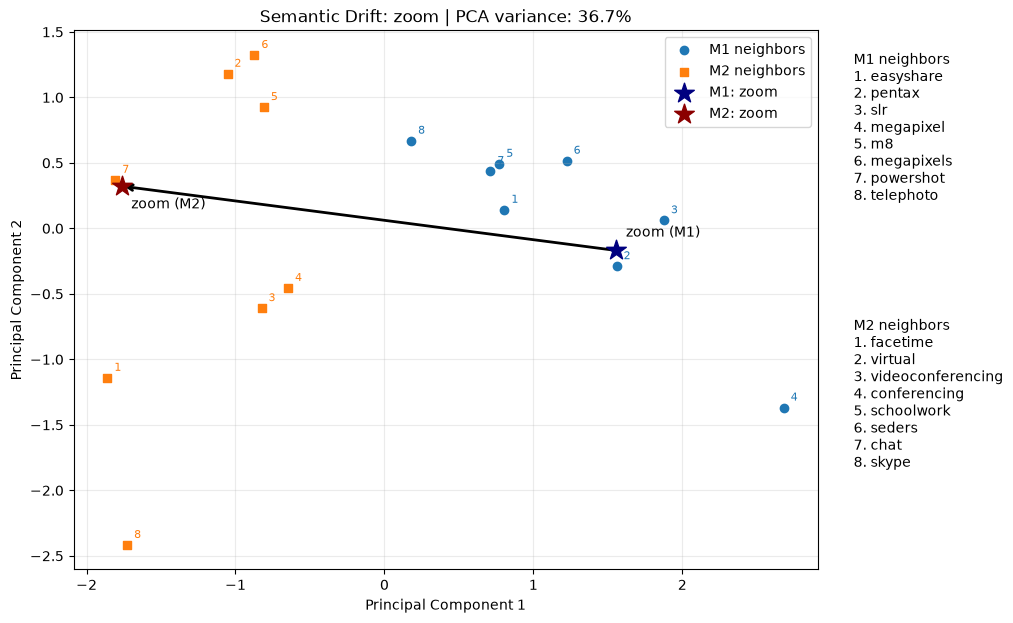

zoom: 18 vectors, 36.7% variance retained


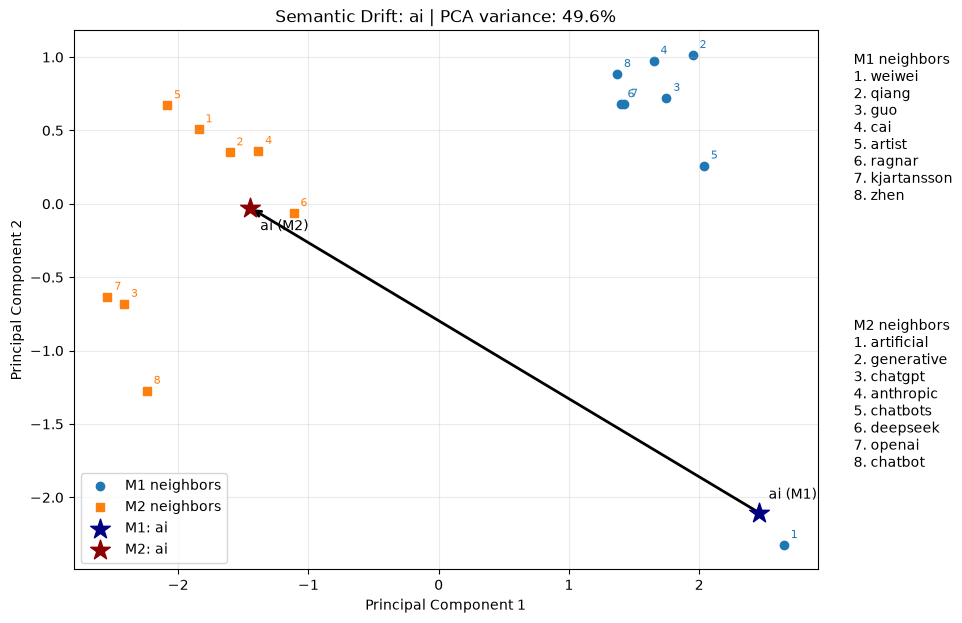

ai: 18 vectors, 49.6% variance retained


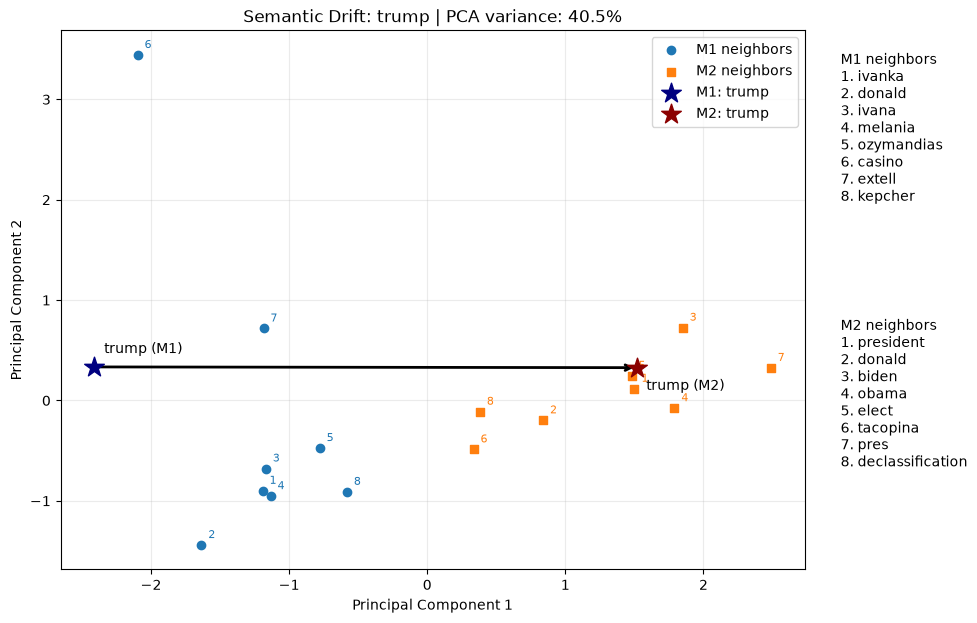

trump: 18 vectors, 40.5% variance retained


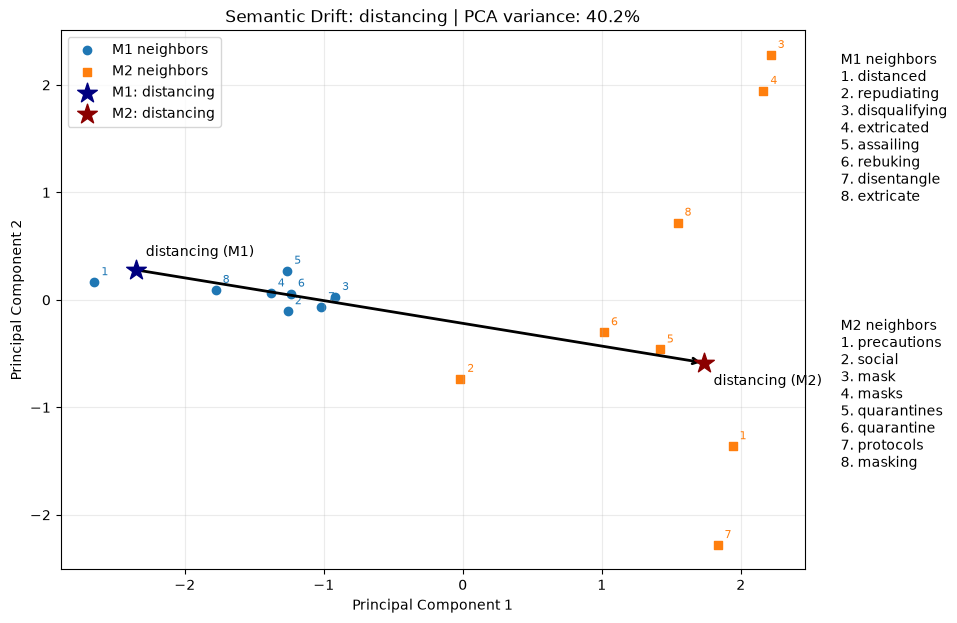

distancing: 18 vectors, 40.2% variance retained


In [19]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def plot_semantic_drift(word):
    # Retrieve eight neighbors from each model.
    old = [w for w, _ in m1.wv.most_similar(word, topn=8)]
    new = [w for w, _ in m2.wv.most_similar(word, topn=8)]

    # Two target vectors and sixteen neighbor vectors.
    vectors = np.vstack(
        [m1.wv[word]] + [m1.wv[w] for w in old]
        + [m2.wv[word]] + [m2.wv[w] for w in new]
    )
    assert vectors.shape == (18, 300)

    # Fit one PCA projection to all eighteen vectors.
    pca = PCA(n_components=2)
    points = pca.fit_transform(vectors)
    variance = pca.explained_variance_ratio_.sum()

    fig, ax = plt.subplots(figsize=(12, 7))
    fig.subplots_adjust(
        left=0.08, right=0.70, top=0.89, bottom=0.12
    )

    # M1 and M2 neighbor positions.
    ax.scatter(
        points[1:9, 0], points[1:9, 1],
        c="tab:blue", marker="o", label="M1 neighbors"
    )
    ax.scatter(
        points[10:18, 0], points[10:18, 1],
        c="tab:orange", marker="s", label="M2 neighbors"
    )

    # Number the neighbors for a readable reference key.
    for start, color in [(1, "tab:blue"), (10, "tab:orange")]:
        for number in range(8):
            i = start + number
            ax.annotate(
                str(number + 1), points[i],
                xytext=(5, 5), textcoords="offset points",
                fontsize=8, color=color
            )

    # Target word positions.
    ax.scatter(
        *points[0], c="navy", marker="*", s=220,
        label=f"M1: {word}", zorder=5
    )
    ax.scatter(
        *points[9], c="darkred", marker="*", s=220,
        label=f"M2: {word}", zorder=5
    )

    # Arrow from M1 target to M2 target.
    ax.annotate(
        "", xy=points[9], xytext=points[0],
        arrowprops=dict(arrowstyle="->", lw=2, color="black")
    )

    ax.annotate(f"{word} (M1)", points[0],
                xytext=(7, 10), textcoords="offset points")
    ax.annotate(f"{word} (M2)", points[9],
                xytext=(7, -16), textcoords="offset points")

    # Neighbor labels outside the scatter plot.
    old_text = "M1 neighbors\n" + "\n".join(
        f"{i}. {w}" for i, w in enumerate(old, 1)
    )
    new_text = "M2 neighbors\n" + "\n".join(
        f"{i}. {w}" for i, w in enumerate(new, 1)
    )

    fig.text(0.73, 0.86, old_text, fontsize=10, va="top")
    fig.text(0.73, 0.48, new_text, fontsize=10, va="top")

    ax.set_title(
        f"Semantic Drift: {word} | PCA variance: {variance:.1%}"
    )
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.grid(alpha=0.25)
    ax.legend(loc="best")

    plt.show()
    plt.close(fig)

    print(f"{word}: 18 vectors, {variance:.1%} variance retained")


# Generate the four required plots.
for word in ["zoom", "ai", "trump", "distancing"]:
    plot_semantic_drift(word)


#### 2.7 Key Findings

The four PCA plots illustrate changes in the contextual associations of `zoom`, `ai`, `trump`, and `distancing` between P1 and P2.

- **Zoom:** Shifts from photography to video conferencing.
- **AI:** Shifts from personal names to artificial intelligence.
- **Trump:** Shifts from family and business associations to presidential politics.
- **Distancing:** Shifts toward pandemic-related terminology.

**Projection method:** PCA was chosen for its simplicity, reproducibility, and linear transformation. Each projection is fitted jointly on all 18 vectors, retaining approximately 36.7% to 49.6% of their variance. The plots illustrate projected changes but cannot capture every relationship in the original 300-dimensional space.

**Vector-space comparison:** M1 and M2 can share a projection because M2 was initialized from M1 and retains approximately the same coordinate system. Google News was trained independently, so plotting its unaligned vectors alongside M1 would produce misleading comparisons. Alignment would be required first.

### 2.8 Emerging Words and Temporal Analogies

We identify the 20 most frequent P2 words absent from M1's vocabulary and examine temporal analogies for ten specified words.

For each target, we retrieve five nearest M1 words using either its continued M2 vector or its Procrustes-aligned M2s vector. These comparisons help identify earlier related concepts and assess where temporal analogies succeed or fail.

In [20]:

import html
from IPython.display import HTML, display

# Load previously computed temporal analogies.
analogy_path = RESULTS / "temporal_analogies.json"
assert analogy_path.is_file(), "Saved analogy results not found."

analogy_results = json.loads(
    analogy_path.read_text(encoding="utf-8")
)

# Part A: Twenty most frequent P2 words absent from M1.
emerging = pd.DataFrame(
    analogy_results["emerging_words"]["words"]
)

assert len(emerging) == 20

emerging_table = emerging[
    ["rank", "word", "m3_count"]
].rename(columns={
    "rank": "Rank",
    "word": "Word",
    "m3_count": "P2 frequency"
})

print("20 Most Frequent P2 Words Absent from M1")
display(emerging_table)

print(
    "Total eligible words:",
    analogy_results["emerging_words"]["available_count"]
)

# Part B: Temporal analogies for the ten required words.
target_words = [
    "covid", "zoom", "trump", "biden", "tiktok",
    "instagram", "netflix", "isis", "pandemic", "brexit"
]

query_results = {
    record["word"]: record
    for record in analogy_results["queries"]
}

assert all(word in query_results for word in target_words)

rows = []

for word in target_words:
    record = query_results[word]

    def format_neighbors(key):
        neighbors = record[key]["neighbors"]
        assert len(neighbors) == 5
        assert all(item["word"] != word for item in neighbors)

        return "<br>".join(
            f"{html.escape(item['word'])} "
            f"({item['cosine_similarity']:.3f})"
            for item in neighbors
        )

    rows.append({
        "Target": html.escape(word),
        "M1 closest to M2": format_neighbors("m1_from_m2"),
        "M1 closest to aligned M2s": format_neighbors(
            "m1_from_m3_aligned"
        )
    })

print("\nTemporal Analogies: Five M1 Neighbors per Method")

display(HTML(
    pd.DataFrame(rows).to_html(
        index=False,
        escape=False
    )
))

print("\nAll ten target words verified.")


20 Most Frequent P2 Words Absent from M1


,Rank,Word,P2 frequency
0,1,coronavirus,17826
1,2,covid,7565
2,3,tiktok,2085
3,4,2023,1717
4,5,brexit,1596
5,6,kyiv,1579
6,7,wordle,1350
7,8,omicron,1195
8,9,macron,1162
9,10,zelensky,1079


Total eligible words: 4966

Temporal Analogies: Five M1 Neighbors per Method


Target,M1 closest to M2,M1 closest to aligned M2s
covid,flu (0.585)vaccine (0.559)swine (0.551)hiv (0.542)ebola (0.523),flu (0.557)vaccine (0.523)swine (0.513)influenza (0.493)hiv (0.490)
zoom,facetime (0.448)gameplay (0.426)animatedly (0.415)conferencing (0.415)quora (0.413),facetime (0.427)keypad (0.412)untethered (0.412)pda (0.412)doodling (0.411)
trump,bush (0.648)obama (0.605)pres (0.544)mccain (0.512)romney (0.511),obama (0.555)bush (0.524)preemptive (0.512)cyberwar (0.498)obstructionism (0.488)
biden,obama (0.695)bush (0.601)president (0.533)romney (0.513)cafta (0.509),obama (0.625)bush (0.594)yoweri (0.470)administration (0.468)drawdown (0.466)
tiktok,youtube (0.608)facebook (0.580)myspace (0.524)twitter (0.507)snapchat (0.495),youtube (0.583)facebook (0.539)myspace (0.495)twitter (0.480)scrabulous (0.475)
instagram,youtube (0.595)twitter (0.589)facebook (0.533)influencers (0.522)thecaucus (0.513),youtube (0.578)twitter (0.570)facebook (0.555)tumblr (0.525)vimeo (0.514)
netflix,syfy (0.537)hbo (0.500)quarterlife (0.478)portlandia (0.475)flashforward (0.474),syfy (0.525)hbo (0.504)portlandia (0.488)flashforward (0.468)serials (0.468)
isis,qaeda (0.635)militants (0.609)mesopotamia (0.602)sunna (0.597)insurgents (0.579),insurgents (0.575)taliban (0.571)militants (0.567)qaeda (0.566)extremist (0.531)
pandemic,recession (0.554)downturn (0.535)decelerating (0.488)joblessness (0.479)hurricane (0.449),downturn (0.506)recession (0.486)hurricane (0.450)katrina (0.446)decelerating (0.432)
brexit,britain (0.484)eu (0.470)austerity (0.454)lse (0.447)tories (0.443),austerity (0.491)eu (0.447)bulgarians (0.440)tories (0.439)drachma (0.438)



All ten target words verified.


#### 2.8 Key Findings

**Emerging words:** The 20 most frequent P2 words absent from M1 include `coronavirus` (17,826), `covid` (7,565), `tiktok` (2,085), and `brexit` (1,596). These reflect changes in news vocabulary, especially around public health, technology, and politics. Absence from M1's vocabulary does not necessarily mean a word was never used during P1.

**Temporal analogies:** Both methods produce several meaningful historical associations:
- `covid` → `flu`, `vaccine`, `swine`
- `tiktok` → `youtube`, `facebook`, `myspace`
- `trump` and `biden` → `bush`, `obama`
- `isis` → `qaeda`, `taliban`
- `brexit` → `eu`, `austerity`

**Limitations:** Some analogies are less meaningful, such as `zoom` → `gameplay` or `biden` → `yoweri`. The `pandemic` analogies emphasize economic crises rather than earlier diseases. These failures may reflect noisy associations, sparse historical contexts, and the limitations of representing different word senses with one vector.

**Conclusion:** Continued M2 and aligned M2s often retrieve similar historical associations, but neither consistently identifies an exact predecessor. Temporal analogies are best interpreted as related historical contexts rather than direct equivalents.